In [15]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.insert(0, "../src")

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import scipy.sparse as sp

from toy_utils import inter_data_le, get_diag_graph, sparsify_sym, aligned_tsne
from ne_aligned_utils.utils import sparsify_affinities

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Data

In [2]:
data = np.load("../data/ot_plan_toy_n01000_n15000_seed0_epstimes1.npz")
P  = data["P"]
x0 = data["x0"]
x1 = data["x1"]
n0, n1 = len(x0), len(x1)
print(f"x0: {x0.shape}, x1: {x1.shape}, P: {P.shape}")

x0: (1000, 3), x1: (5000, 3), P: (1000, 5000)


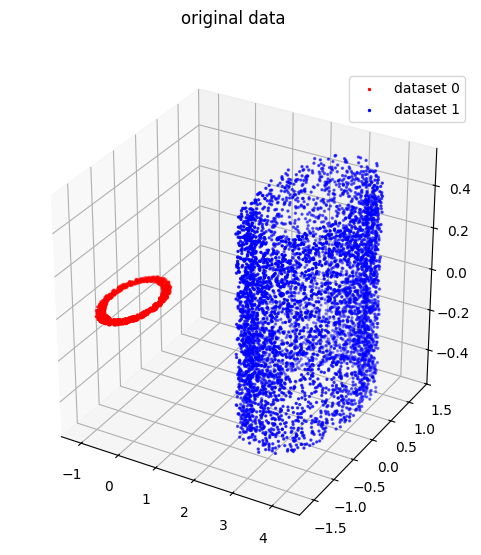

In [3]:
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(*x0.T, c="r", s=2, label="dataset 0")
ax.scatter(*x1.T, c="b", s=2, label="dataset 1")
ax.set_box_aspect([1, 1, 1])
ax.legend()
fig.suptitle("original data")
plt.show()

In [4]:
U, S, V = np.linalg.svd(P, full_matrices=False)

In [5]:
t = 0
eot0_embd = np.concatenate([U * S**t * np.sqrt(n0),
                       V.T *S**t * np.sqrt(n1)], axis=0)
t = 1
eot1_embd = np.concatenate([U * S**t * np.sqrt(n0),
                       V.T *S**t * np.sqrt(n1)], axis=0)

t = 0.5
eot_half_embd = np.concatenate([U * S**t * np.sqrt(n0),
                       V.T *S**t * np.sqrt(n1)], axis=0)

In [6]:
P_diag = eot_half_embd @ eot_half_embd.T / (np.sqrt(n0 * n1))

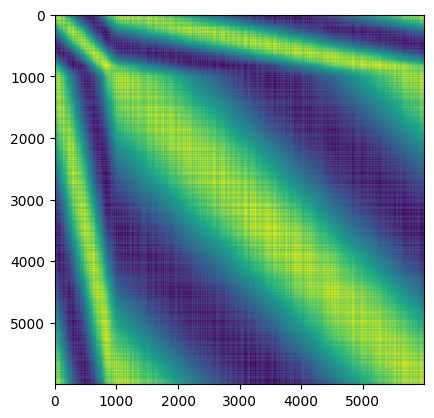

In [7]:
plt.imshow(P_diag, interpolation='none')

## Laplacian Eigenmaps

In [8]:
embd0_le, embd1_le = inter_data_le(P, q=2)
print(embd0_le.shape, embd1_le.shape)

(1000, 2) (5000, 2)


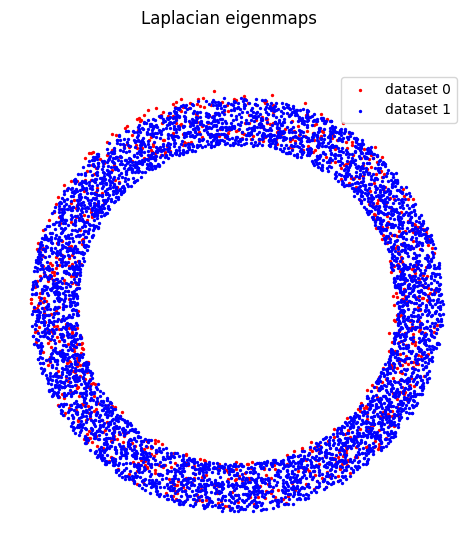

In [10]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(*embd0_le.T, c="r", s=2, label="dataset 0")
ax.scatter(*embd1_le.T, c="b", s=2, label="dataset 1")
ax.set_aspect("equal")
ax.axis("off")
ax.legend()
fig.suptitle("Laplacian eigenmaps")
plt.show()

## Aligned tSNE with sym sparse diagonal graph

In [11]:
A = get_diag_graph(P)
graph = sparsify_sym(A, n0, n1, k=15)
print(f"graph: {graph.shape}, nnz: {graph.nnz}")

graph: (6000, 6000), nnz: 346832


In [12]:
embd_tsne = aligned_tsne(graph, n_epochs=200, seed=0)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=500.00 for 66 iterations...
Iteration   50, KL divergence 4.3752, 50 iterations in 2.1173 sec
   --> Time elapsed: 2.59 seconds
===> Running optimization with exaggeration=1.00, lr=6000.00 for 134 iterations...
Iteration   50, KL divergence 2.2392, 50 iterations in 1.2094 sec
Iteration  100, KL divergence 2.2040, 50 iterations in 1.1378 sec
   --> Time elapsed: 3.03 seconds


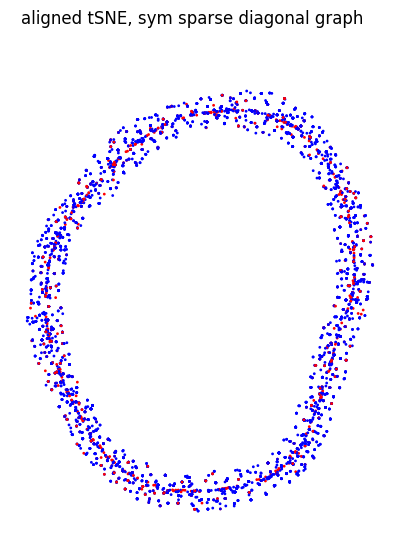

In [13]:
fig, ax = plt.subplots(figsize=(6, 6))
colors = ["r"] * n0 + ["b"] * n1
order = np.random.permutation(n0 + n1)
ax.scatter(*embd_tsne[order].T, c=np.array(colors)[order], s=1)
ax.set_aspect("equal")
ax.axis("off")
fig.suptitle("aligned tSNE, sym sparse diagonal graph")
plt.show()

## Comparing Sparsification Methods 


In [16]:
k = 15

def sparsify_weighted_flat_sym(A, n0, n1, k=15):
    A_sp = np.zeros_like(A)
    for row_slice, col_slice in [
        (slice(None, n0), slice(None, n0)),   # intra-x0
        (slice(None, n0), slice(n0, None)),   # x0 -> x1
        (slice(n0, None), slice(None, n0)),   # x1 -> x0
        (slice(n0, None), slice(n0, None)),   # intra-x1
    ]:
        block = A[row_slice, col_slice]
        n_rows = block.shape[0]
        idx = block.argsort(axis=1)[:, -k:]
        rows = np.arange(n_rows)[:, None]
        A_sp[row_slice, col_slice][rows, idx] = block[rows, idx]
    A_sp = np.maximum(A_sp, A_sp.T)
    np.fill_diagonal(A_sp, 0)
    return sp.csr_matrix(A_sp / A_sp.sum())
graphs = {}

# 1. flat binary symmetric 
graphs["flat_bin_sym"]    = graph  

# 2. scaled binary symmetric
graphs["scaled_bin_sym"]  = sp.csr_matrix(sparsify_affinities(A, n0, n1, k=k, symmetric=True))

# 3. scaled binary asymmetric
graphs["scaled_bin_nosym"] = sp.csr_matrix(sparsify_affinities(A, n0, n1, k=k, symmetric=False))

# 4. weighted flat symmetric
graphs["flat_wt_sym"]     = sparsify_weighted_flat_sym(A, n0, n1, k=k)

# 5. no sparsification
A_dense = A.copy()
np.fill_diagonal(A_dense, 0)
graphs["no sparsification"]           = sp.csr_matrix(A_dense / A_dense.sum())

print(f"{'name':<20}  {'nnz':>8}  {'fill%':>7}  "
      f"{'intra-x0 k̄':>10}  {'cross k̄':>9}  {'intra-x1 k̄':>10}")
N = n0 + n1
for name, g in graphs.items():
    A_full = g.toarray() if sp.issparse(g) else g
    A_bin  = (A_full > 0).astype(float)
    nnz    = int((A_bin > 0).sum())
    fill   = 100 * nnz / (N * N)
    k_00   = A_bin[:n0, :n0].sum(1).mean()
    k_cross= A_bin[:n0, n0:].sum(1).mean()
    k_11   = A_bin[n0:, n0:].sum(1).mean()
    print(f"{name:<20}  {nnz:>8d}  {fill:>6.3f}%  "
          f"{k_00:>10.1f}  {k_cross:>9.1f}  {k_11:>10.1f}")

name                       nnz    fill%  intra-x0 k̄   cross k̄  intra-x1 k̄
flat_bin_sym            346832   0.963%        27.4       87.0        29.1
scaled_bin_sym          984796   2.736%        27.4      137.0       136.7
scaled_bin_nosym        540000   1.500%        15.0       75.0        75.0
flat_wt_sym             346832   0.963%        27.4       87.0        29.1
no sparsification     35994000  99.983%       999.0     5000.0      4999.0


In [17]:
# run aligned t-SNE for each sparsification method (takes a few minutes for 'dense')
embds = {}
for name, g in graphs.items():
    print(f"\n=== {name} ===")
    embds[name] = aligned_tsne(g, n_epochs=200, seed=0)


=== flat_bin_sym ===
--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------------
===> Running optimization with exaggeration=12.00, lr=500.00 for 66 iterations...
Iteration   50, KL divergence 4.5004, 50 iterations in 2.0761 sec
   --> Time elapsed: 2.49 seconds
===> Running optimization with exaggeration=1.00, lr=6000.00 for 134 iterations...
Iteration   50, KL divergence 2.3034, 50 iterations in 1.1862 sec
Iteration  100, KL divergence 2.2720, 50 iterations in 0.7649 sec
   --> Time elapsed: 2.35 seconds

=== scaled_bin_sym ===
--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, early_exaggeration_iter=66, n_iter=134,
     random_state=0, verbose=True)
--------------------------------------------------------------------------

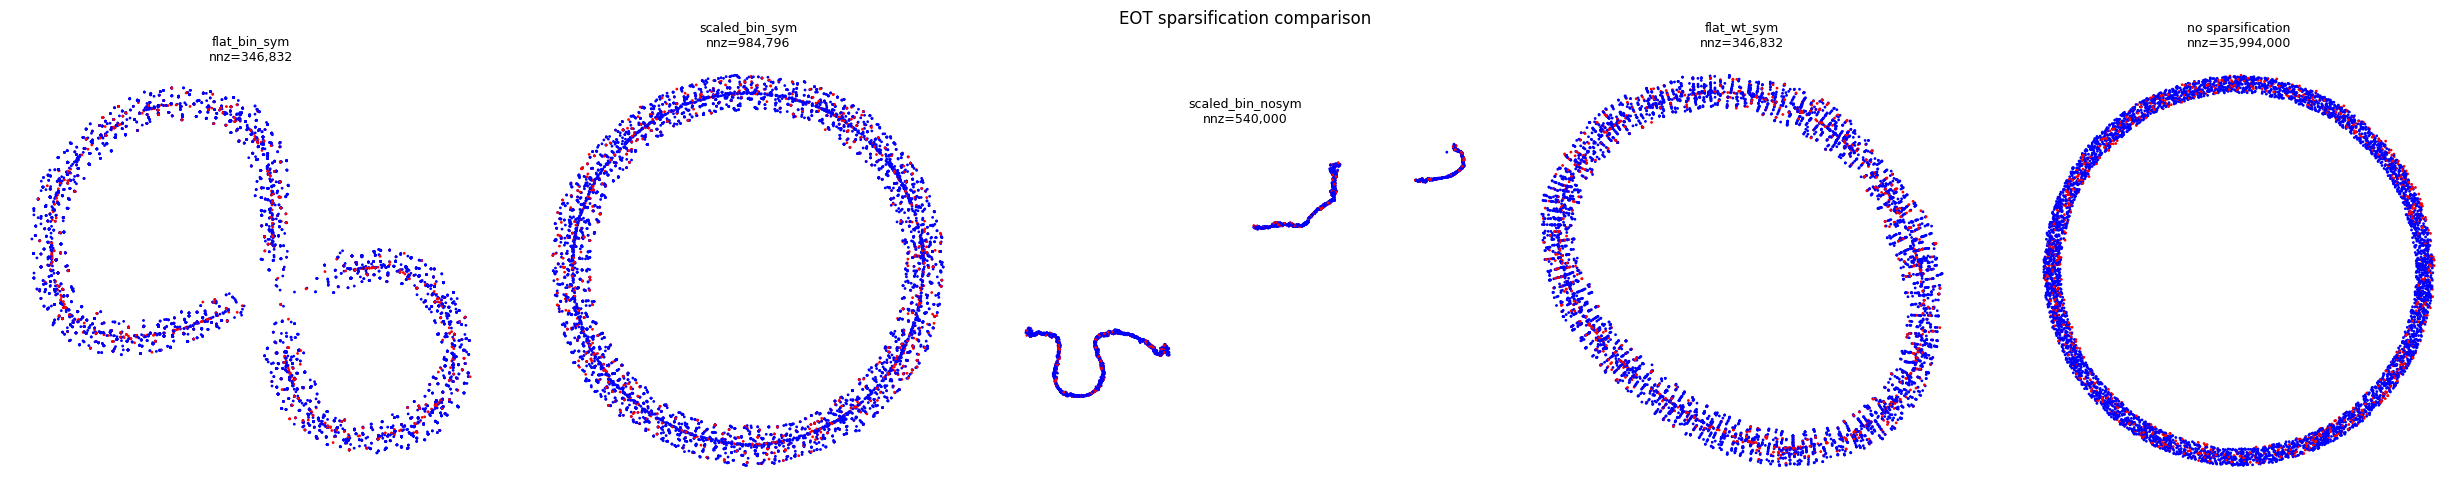

In [18]:
fig, axes = plt.subplots(1, len(embds), figsize=(5 * len(embds), 5))
colors = np.array(["r"] * n0 + ["b"] * n1)
order = np.random.permutation(n0 + n1)

for ax, (name, embd) in zip(axes, embds.items()):
    ax.scatter(*embd[order].T, c=colors[order], s=1, rasterized=True)
    ax.set_aspect("equal")
    ax.axis("off")
    g = graphs[name]
    nnz = g.nnz
    ax.set_title(f"{name}\nnnz={nnz:,}", fontsize=9)

fig.suptitle("EOT sparsification comparison")
fig.tight_layout()
plt.show()

# TO DO'S
- think about the metrics
    - concordance seems to work
    - Sebastian did not look to deeply into cross concordance 
    - maybe other metric that might be interesting???
- vary hyperparameters
    - k not so interesting
    - theta parameter of gaussian bumps
- how to sparsify transport plan
    - Percentage of neighbors
    - Percentage of probability mass
    - percentage below top value

- test multiple seeds
